Matriz de confusão:
[[924 111]
 [190 184]]

Relatório de classificação:
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.62      0.49      0.55       374

    accuracy                           0.79      1409
   macro avg       0.73      0.69      0.71      1409
weighted avg       0.77      0.79      0.78      1409

ROC-AUC: 0.8251


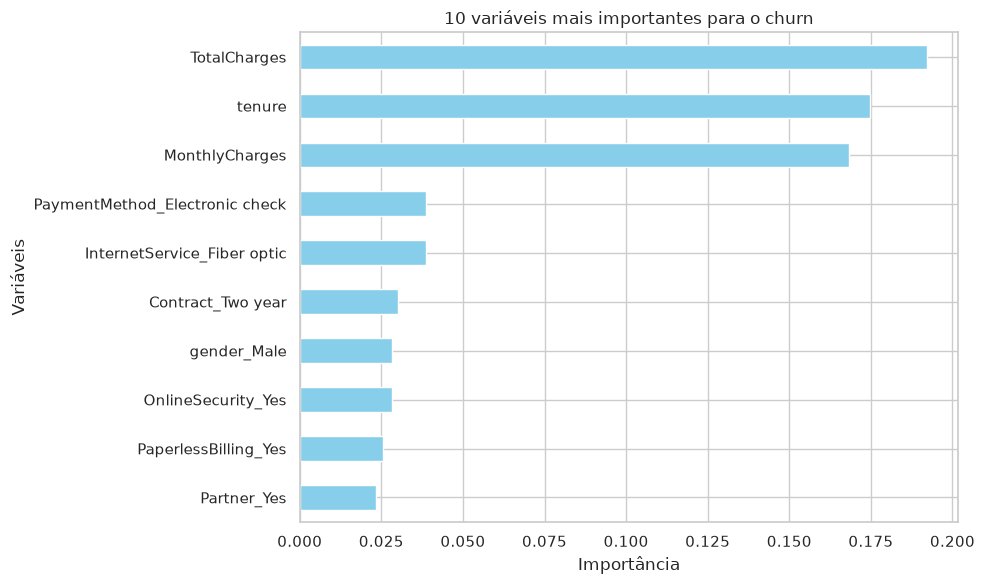

In [2]:
import os
import glob
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
)

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

arquivos = glob.glob("/workspaces/**/churn_processed.csv", recursive=True)
if not arquivos:
    raise FileNotFoundError(
        "O arquivo 'churn_processed.csv' não foi encontrado. "
        "Execute primeiro o notebook de preparação dos dados."
    )

df = pd.read_csv(arquivos[0])
if "Churn" not in df.columns:
    raise ValueError("A coluna 'Churn' não existe no dataset.")

X = pd.get_dummies(df.drop(columns=["Churn"]), drop_first=True)
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y,
)

modelo = RandomForestClassifier(n_estimators=100, random_state=42)
modelo.fit(X_train, y_train)

y_pred = modelo.predict(X_test)
y_prob = modelo.predict_proba(X_test)[:, 1]

print("Matriz de confusão:")
print(confusion_matrix(y_test, y_pred))

print("\nRelatório de classificação:")
print(classification_report(y_test, y_pred))
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob):.4f}")

importancia = pd.Series(
    modelo.feature_importances_,
    index=X.columns,
).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
importancia.head(10).sort_values().plot(kind="barh", color="skyblue")
plt.title("10 variáveis mais importantes para o churn")
plt.xlabel("Importância")
plt.ylabel("Variáveis")
plt.tight_layout()
plt.show()
